Importation des librairies

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

Chargement du fichier texte

In [ ]:
# Chargement et nettoyage du texte ligne par ligne
with open('data/victor-hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip()]

print(f"Exemple de texte : {texts[0]}")

Exemple de texte : Mes vers fuiraient


Tokenisation du texte (mots -> nombres)

In [4]:
vocab_size = 1000
window_size = 3

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

Création des données d'entraînement (X et y)

In [5]:
X = []
y = []

# Pour chaque séquence, on prend au plus les 3 mots précédents (X) pour deviner le suivant (y)
for seq in sequences:
    for i in range(1, len(seq)):
        start_index = max(0, i - window_size)
        X.append(seq[start_index:i])
        y.append(seq[i])

# On remplit avec des zéros (padding) si on a moins de 3 mots de contexte
X = pad_sequences(X, maxlen=window_size, padding='pre')
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (11541, 3), y shape: (11541,)


Création de l'architecture du modèle (SimpleRNN)

In [6]:
embedding_dim = 16

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    SimpleRNN(32),
    Dense(vocab_size, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Entraînement du modèle

In [9]:
# Arrêt anticipé pour éviter l'overfitting et gagner du temps
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2689 - loss: 3.5005
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2732 - loss: 3.4637
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2821 - loss: 3.4341
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2865 - loss: 3.4039
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2891 - loss: 3.3749
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2926 - loss: 3.3463
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2967 - loss: 3.3186
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3021 - loss: 3.2893
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3073 - loss: 3.2645
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3112 - loss: 3.2389
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3151 - loss: 3.2130
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

Visualisation de l'erreur (Loss)

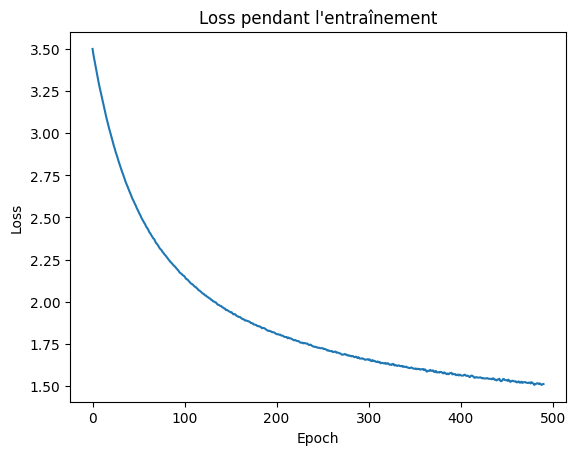

In [10]:
plt.plot(history.history['loss'])
plt.title("Loss pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

Fonction de génération de texte

In [11]:
def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # On garde les "window_size" derniers mots, et on met des zéros si besoin
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')

        probs = model.predict(tokens, verbose=0)[0]

        # Application de la température pour le tirage (créatif vs prévisible)
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None:
            text += " " + word

    return text

Test de génération

In [12]:
random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème à ses bêtes peut ô bon vois la jeune et la chanson la tour sans couleur de aimons du qui les âmes les voix les les parmi tous un vallon chacun tourmente à cette être tombe le soir sur la source notre sourire s'envolent aux morts que vos doute et


Évolution vers un modèle LSTM

In [13]:
from tensorflow.keras.layers import LSTM

embedding_dim = 16
model_lstm = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    LSTM(64),
    Dense(vocab_size, activation='softmax')
])

model_lstm.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model_lstm.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Entraîner le modèle LSTM (température)

In [14]:
# Utilisation du même arrêt anticipé
early_stop_lstm = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

# Entraînement du LSTM avec les mêmes données X et y
print("--- Entraînement du modèle LSTM ---")
history_lstm = model_lstm.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop_lstm]
)

--- Entraînement du modèle LSTM ---
Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.0340 - loss: 6.1640
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0346 - loss: 5.8687
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0350 - loss: 5.8091
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0354 - loss: 5.7542
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0386 - loss: 5.7166
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0401 - loss: 5.6801
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0447 - loss: 5.6288
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0494 - loss: 5.5665
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0535 - loss: 5.5041
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0558 - loss: 5.4492
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0566 - loss: 5.3975
Epoch

Comparer la Loss (Erreur)

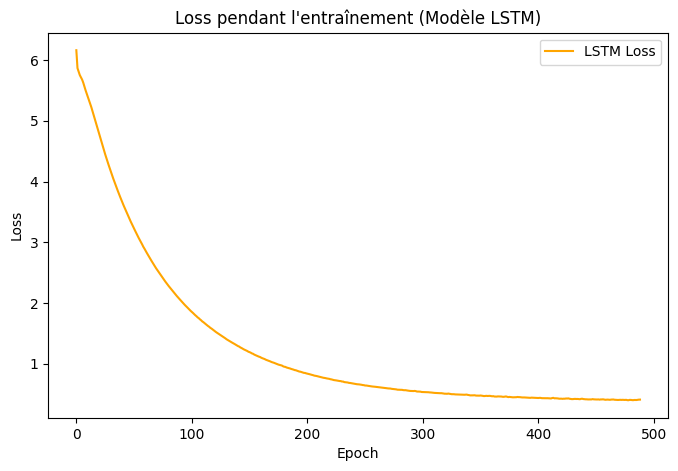

In [15]:
# Affichage de la loss du LSTM
plt.figure(figsize=(8, 5))
plt.plot(history_lstm.history['loss'], color='orange', label='LSTM Loss')
plt.title("Loss pendant l'entraînement (Modèle LSTM)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Tester la génération de texte avec différentes "températures"

In [16]:
def generate_text_lstm(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # On garde les "window_size" derniers mots
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')

        # Prédiction avec le modèle LSTM
        probs = model_lstm.predict(tokens, verbose=0)[0]

        # Application de la température
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None:
            text += " " + word

    return text

print("--- Température très basse (0.2) : Prévisible et répétitif ---")
print(generate_text_lstm("le poète", num_words=30, temperature=0.2))

print("\n--- Température moyenne (0.8) : Bon équilibre créatif ---")
print(generate_text_lstm("le poète", num_words=30, temperature=0.8))

print("\n--- Température élevée (1.5) : Créatif mais chaotique ---")
print(generate_text_lstm("le poète", num_words=30, temperature=1.5))

--- Température très basse (0.2) : Prévisible et répétitif ---
le poète au siècle où nous sommes criant malheur malheur on le sa le et qui mit à travers les rayons de ses jours la vie aux mille soins et lourds chose

--- Température moyenne (0.8) : Bon équilibre créatif ---
le poète en divin joyeux sans qui et s'en vont la vie par sa grève par le vent qui vient à travers la montagne me rendra fou tout nature qu'il ce désert

--- Température élevée (1.5) : Créatif mais chaotique ---
le poète est divin joyeux front vient sur la nuit d'où tout » au plein à soleil dans la brume qui la nuit aux mille dans l'abîme et s'en va dans la


Conclusion pour les températures:\
À 0.2, l'IA ne prend aucun risque. Elle choisit toujours le mot qui a la plus forte probabilité. Résultat : le texte tourne en boucle sur les mêmes mots (ex: "le poète de la mer de la mer...").\
À 0.8, on a un bon équilibre entre la logique et l'originalité.\
À 1.5, l'IA prend trop de risques et tire des mots presque au hasard, la grammaire s'effondre.

# **Réponses aux 10 questions**

Qu'est-ce que fait le Tokenizer et pourquoi est-il nécessaire ? \
Il convertit les mots en nombres entiers (indices). Les réseaux de neurones ne peuvent faire des calculs que sur des valeurs numériques, ils ne comprennent pas le texte brut.

Pourquoi utilise-t-on pad_sequences et que se passerait-il si on ne l'utilisait pas ?\
Le réseau attend toujours des entrées de taille fixe (ici 3 mots). Si une séquence n'a que 1 ou 2 mots, pad_sequences ajoute des zéros au début pour combler. Sans cela, Keras générerait une erreur mathématique de dimension.

Quelle est la différence entre vocab_size et embedding_dim ?\
vocab_size (1000) est la taille du dictionnaire (le nombre total de mots uniques que le modèle connaît). embedding_dim (16) est la taille du vecteur mathématique qui va représenter la "signification" de chaque mot dans l'espace.

En quoi consiste une couche Embedding et pourquoi on l'utilise avant le RNN ?\
Elle sert à donner un "sens spatial" aux mots. Au lieu d'utiliser de simples numéros (qui n'ont pas de sens logique entre eux), l'Embedding transforme les mots en vecteurs denses où des mots aux sens similaires seront physiquement proches. C'est essentiel pour que le RNN comprenne le contexte.

Quelle est la différence entre SimpleRNN et LSTM ? Dans quel cas préférer un LSTM ?\
Un SimpleRNN a la "mémoire courte" (il oublie vite les premiers mots de la phrase à cause du problème du vanishing gradient). Un LSTM (Long Short-Term Memory) possède un système de "portes" qui lui permet de mémoriser ou d'oublier intelligemment des informations à long terme. On préfère toujours le LSTM pour du texte long.

Que représente window_size = 3 et comment cela influence-t-il l'apprentissage ?\
C'est la fenêtre de contexte : le réseau s'appuie uniquement sur les 3 mots précédents pour deviner le suivant. Une fenêtre trop courte produit un texte avec une bonne grammaire de base mais sans aucun sens logique sur la durée de la phrase.

Pourquoi utilise-t-on sparse_categorical_crossentropy dans ce cas précis ?\
Notre cible (y) est l'indice numérique du mot à deviner. Si on utilisait categorical_crossentropy, il faudrait créer pour chaque mot un tableau géant de 1000 zéros avec un seul "1" (One-Hot), ce qui consommerait énormément de RAM. Le terme sparse permet d'utiliser l'entier directement.

Que fait le callback EarlyStopping, et pourquoi est-il utile ici ?\
Il surveille l'évolution de la fonction de perte (loss). Si celle-ci arrête de s'améliorer pendant 10 passages (patience=10), l'entraînement s'interrompt. Cela fait gagner beaucoup de temps et évite au modèle d'apprendre par cœur les données (overfitting).

En observant la courbe de la loss pendant l'entraînement, comment peut-on savoir si le modèle converge bien ?\
La courbe doit descendre de façon fluide et continue, puis s'aplatir peu à peu vers le bas. Si elle stagne très haut, oscille violemment ou commence à remonter, c'est qu'il y a un problème d'apprentissage.

Analyse le texte généré : est-il grammaticalement correct et cohérent ? \Pourquoi le modèle n'arrive-t-il pas encore à écrire comme Victor Hugo ?\
Le texte est généralement bon grammaticalement au niveau des petits groupes de mots (ex: Un déterminant est bien suivi d'un nom). Mais il est incohérent sur le long terme car le modèle manque de puissance : son vocabulaire est très faible (1000 mots), son contexte est minuscule (3 mots) et son architecture est basique (Loin de la puissance des Transformers récents comme ChatGPT).